# 07 - Summary of the parameter sweeps

One-dose combination treatment (antibiotic + beta-lactamase inhibitor) of a mixed sensitive (S) and
resistant (R) population, using the model of Ma et al. (2024, *Nat Commun* 15:8337). The group's
question: **which parameters decide whether R is removed while S is kept, and how deep is the crash
on the way?**

This notebook only reads the tables in `results/tables/`. Most are written by `01_run_sweeps.ipynb`;
notebooks 00, 06 and 08-11 each write the tables for their own section.

| Notebook | Content |
|---|---|
| `00_model_verification` | checks that the code is the paper's model and that numerics do not matter |
| `01_run_sweeps` | runs every sweep on one consistent grid and saves the tables |
| `02_alpha_betamin_c` | cost of resistance and private benefit |
| `03_gamma_ha_a0` | antibiotic killing and dose |
| `04_inhibitor_i_hi_db` | inhibitor dose and action |
| `05_kappab_da_phimax_xi` | antibiotic degradation and nutrient recycling |
| `06_criterion_validation` | the paper's selection criterion |
| `07_summary` | this notebook |
| `08_dose_by_trait` | dose plane × α, β_min, c (runs its own sweep) |
| `09_fine_grid_low_degradation` | fine grid in the low φ_max, κ_b corner (runs its own sweep) |
| `10_killing_vs_protection` | is the relation between killing rate γ and R's private protection linear? (runs its own sweep) |
| `11_gamma_vs_phimax` | is the relation between γ and degradation by living R (φ_max) linear? (runs its own sweep) |

In [1]:
from pathlib import Path
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
TABLES = PROJECT_ROOT / "results" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", None); pd.set_option("display.width", 160)

from dataclasses import replace, asdict
from src.model.ma2024_model import DEFAULT_PARAMS, SI_INITIAL_CONDITIONS, BASE_A0, BASE_I
from src.analysis import sweep_engine as engine
from src.analysis.grid_runner import axis, BASE_VALUES, RANGES, LOG_AXES, N_PER_AXIS
from src.analysis.plotting import (heatmap_slices, pair_heatmaps, outcome_map, outcome_counts, select,
                                   label, SHORT, OKABE_ITO, OUTCOME_COLORS)

GRIDS = {"α, β_min, c": ("grid_alpha_betamin_c.csv", ["alpha", "beta_min", "c"]),
         "γ, h_a, a0": ("grid_gamma_ha_a0.csv", ["gamma", "h_a", "a0"]),
         "i, h_i, d_b": ("grid_i_hi_db.csv", ["i", "h_i", "d_b"]),
         "κ_b, d_a, φ_max, ξ": ("grid_kappab_da_phimax_xi.csv.gz", ["kappa_b", "d_a", "phi_max", "xi"])}
grids = {name: pd.read_csv(TABLES / f) for name, (f, _) in GRIDS.items()}
oat = pd.read_csv(TABLES / "sweep_one_at_a_time.csv")
rnd = pd.read_csv(TABLES / "sweep_global_random.csv")
dose = pd.read_csv(TABLES / "grid_dose_a0_i.csv")
crit = pd.read_csv(TABLES / "grid_criterion_a0_100.csv")
checks = pd.read_csv(TABLES / "model_verification_checks.csv")
STRAIN_PARAMS = [k for k in RANGES if k not in ("a0", "i")]
print({name: len(df) for name, df in grids.items()}, "| one-at-a-time:", len(oat), "| random strains:", len(rnd),
      "| dose plane:", len(dose), "| criterion grid:", len(crit))

{'α, β_min, c': 9261, 'γ, h_a, a0': 10164, 'i, h_i, d_b': 9261, 'κ_b, d_a, φ_max, ξ': 194481} | one-at-a-time: 535 | random strains: 10000 | dose plane: 1848 | criterion grid: 9261


## 1. Model, base parameters and grid

Five state variables (S, R, nutrient, antibiotic, free enzyme), Supplementary Eqs. S1-S10. All base
values, initial conditions and ranges are the paper's Supplementary Information values, except the
range of d_a (0-0.1), which the paper does not randomize and is the group's choice. Every sweep
uses the same rule: 21 evenly spaced values over the SI randomized range (log-spaced for the two
doses) plus the base value where it is not already on the grid; everything not being swept stays at
base and at the Fig. 2C dose.

In [2]:
design = pd.DataFrame([{
    "parameter": SHORT[k], "meaning": label(k).split("(")[-1].rstrip(")"), "base": BASE_VALUES[k],
    "min": RANGES[k][0], "max": RANGES[k][1], "spacing": "log" if k in LOG_AXES else "linear",
    "values on axis": len(axis(k)),
    "swept in": next((name for name, (_, ps) in GRIDS.items() if k in ps), ""),
    "range source": ("group choice" if k == "d_a" else "SI dose range" if k in ("a0", "i") else "SI randomized range"),
} for k in RANGES]).set_index("parameter")
print("Initial conditions:", SI_INITIAL_CONDITIONS, "| base dose: a0 =", BASE_A0, ", i =", BASE_I)
design

Initial conditions: {'ns0': 0.2, 'nr0': 0.2, 's0': 4.0, 'b0': 0.0} | base dose: a0 = 2.15 , i = 10.0


,meaning,base,min,max,spacing,values on axis,swept in,range source
parameter,,,,,,,,
α,growth of R relative to S,0.95,0.75,1.0,linear,21,"α, β_min, c",SI randomized range
β_min,1 = no private protection,0.90,0.00,1.0,linear,21,"α, β_min, c",SI randomized range
c,inhibitor efficacy inside R,0.70,0.00,1.0,linear,21,"α, β_min, c",SI randomized range
γ,maximum lysis,1.38,1.10,1.4,linear,22,"γ, h_a, a0",SI randomized range
h_a,antibiotic Hill coefficient,3.00,1.00,5.0,linear,21,"γ, h_a, a0",SI randomized range
h_i,inhibitor Hill coefficient,2.00,1.00,5.0,linear,21,"i, h_i, d_b",SI randomized range
κ_b,degradation by free enzyme,0.35,0.00,1.0,linear,21,"κ_b, d_a, φ_max, ξ",SI randomized range
d_b,enzyme inactivation by inhibitor,1.00,1.00,10.0,linear,21,"i, h_i, d_b",SI randomized range
ξ,nutrient recycling,0.80,0.00,1.0,linear,21,"κ_b, d_a, φ_max, ξ",SI randomized range


## 2. Model verification

All checks from `00_model_verification.ipynb`.

In [3]:
checks["group"] = checks.check.str.extract(r"^(\d+)")[0].map({
    "1": "1 equations vs SI", "2": "2 Fig. 2C reproduced", "3": "3 Fig. 2D / 3A reproduced",
    "4": "4 engine vs reference", "5": "5 solver independence", "6": "6 balances and positivity",
    "7": "7 exact identities", "8": "8 sampling and horizon", "9": "9 handled behaviours"})
print(f"{int(checks['pass'].sum())} of {len(checks)} checks passed")
assert checks["pass"].all()
checks.groupby("group").agg(checks=("pass", "size"), passed=("pass", "sum"))

34 of 34 checks passed


,checks,passed
group,,
1 equations vs SI,1,1
2 Fig. 2C reproduced,3,3
3 Fig. 2D / 3A reproduced,7,7
4 engine vs reference,1,1
5 solver independence,2,2
6 balances and positivity,5,5
7 exact identities,8,8
8 sampling and horizon,5,5
9 handled behaviours,2,2


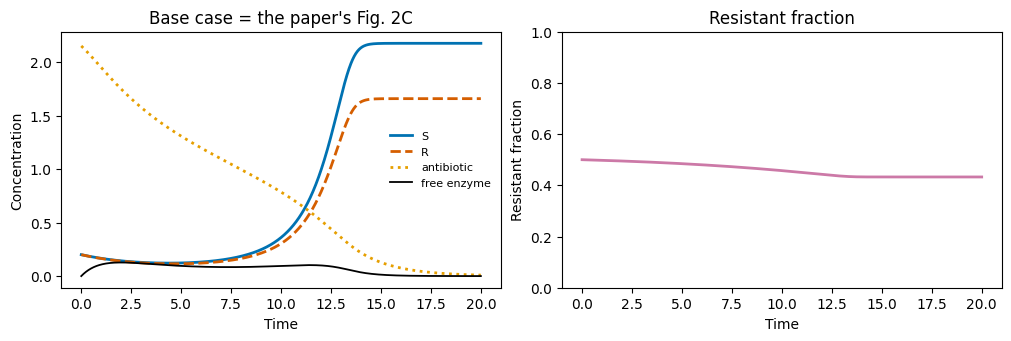

Base case: final S = 2.17, R = 1.66, f_R = 0.433; peak S loss = 39.4%; S back to its starting density at t = 8.5; steady state at t = 15.5


In [4]:
tr = engine.simulate(DEFAULT_PARAMS, BASE_A0, BASE_I, t_end=20, dt=0.02)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.3), constrained_layout=True)
ax.plot(tr.t, tr.ns, color=OKABE_ITO["blue"], lw=2, label="S"); ax.plot(tr.t, tr.nr, color=OKABE_ITO["vermillion"], lw=2, ls="--", label="R")
ax.plot(tr.t, tr.a, color=OKABE_ITO["orange"], lw=2, ls=":", label="antibiotic"); ax.plot(tr.t, tr.b, color="black", lw=1.3, label="free enzyme")
ax.set(xlabel="Time", ylabel="Concentration", title="Base case = the paper's Fig. 2C"); ax.legend(frameon=False, fontsize=8)
ax2.plot(tr.t, tr.nr / (tr.ns + tr.nr), color=OKABE_ITO["purple"], lw=2); ax2.set(xlabel="Time", ylabel="Resistant fraction", ylim=(0, 1), title="Resistant fraction")
plt.show()
b = engine.compute_endpoints()
print(f"Base case: final S = {b['ns_final']:.2f}, R = {b['nr_final']:.2f}, f_R = {b['f_R_final']:.3f}; peak S loss = {b['peak_loss_S']:.1%}; "
      f"S back to its starting density at t = {b['t_regain_S']}; steady state at t = {b['t_steady_state']}")

## 3. The sweeps are consistent with each other

In [5]:
check_cols = ["f_R_final", "ns_final", "nr_final", "peak_loss_S", "t_regain_S", "t_steady_state"]
rows, base_rows = [], []
for name, df in grids.items():
    ps = GRIDS[name][1]
    base = select(df, {k: BASE_VALUES[k] for k in ps})
    assert len(base) == 1
    base_rows.append(base[check_cols].iloc[0].rename(name))
    rows.append({"sweep": name, "runs": len(df), "values per axis": " × ".join(str(df[k].nunique()) for k in ps),
                 "settled": int((~df.outcome.isin(["community collapsed", "not converged"])).sum()),
                 "collapsed (drug never clears)": int((df.outcome == "community collapsed").sum()),
                 "not converged": int((df.outcome == "not converged").sum()),
                 "needed t > 150": int((df.t_end > 150).sum())})
base_table = pd.DataFrame(base_rows)
assert np.allclose(base_table.values, base_table.values[0], rtol=1e-6)
display(pd.DataFrame(rows).set_index("sweep"))
print("The base point gives the same result in all four grids:")
base_table.round(4)

,runs,values per axis,settled,collapsed (drug never clears),not converged,needed t > 150
sweep,,,,,,
"α, β_min, c",9261,21 × 21 × 21,9261,0,0,0
"γ, h_a, a0",10164,22 × 21 × 22,10164,0,0,3568
"i, h_i, d_b",9261,21 × 21 × 21,9261,0,0,0
"κ_b, d_a, φ_max, ξ",194481,21 × 21 × 21 × 21,194128,350,3,462


The base point gives the same result in all four grids:


,f_R_final,ns_final,nr_final,peak_loss_S,t_regain_S,t_steady_state
"α, β_min, c",0.4326,2.1746,1.6577,0.3944,8.5,15.5
"γ, h_a, a0",0.4326,2.1746,1.6577,0.3944,8.5,15.5
"i, h_i, d_b",0.4326,2.1746,1.6577,0.3944,8.5,15.5
"κ_b, d_a, φ_max, ξ",0.4326,2.1746,1.6577,0.3944,8.5,15.5


## 4. Which parameters matter? All 13 on one scale

**One at a time.** Each parameter is varied alone over its full range with everything else at base.
The bars show how far each endpoint moves (largest minus smallest value over the range), so the
parameters can be compared directly. This is the decoupled view.

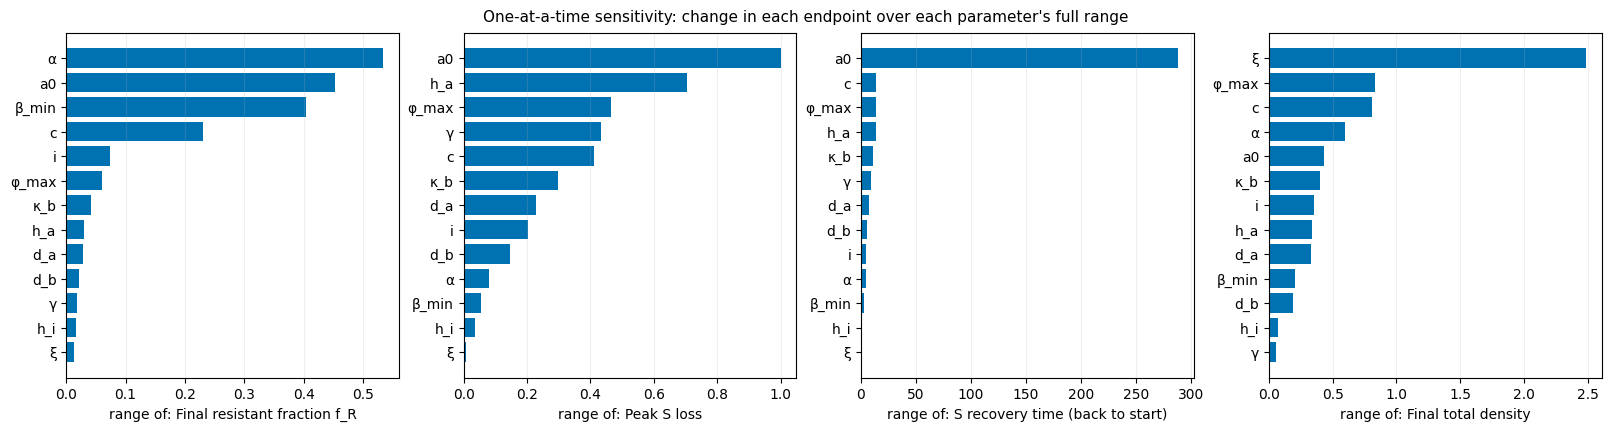

,f_R_final,peak_loss_S,t_regain_S,total_final
parameter,,,,
α,0.534,0.079,5.0,0.597
a0,0.453,1.000,288.0,0.431
β_min,0.404,0.054,3.0,0.202
c,0.230,0.410,14.0,0.807
i,0.073,0.203,5.0,0.355
φ_max,0.061,0.464,14.0,0.833
κ_b,0.041,0.298,10.5,0.399
h_a,0.029,0.704,13.5,0.336
d_a,0.028,0.228,7.0,0.332


In [6]:
ENDS = ["f_R_final", "peak_loss_S", "t_regain_S", "total_final"]
ok = oat[~oat.outcome.isin(["community collapsed", "not converged"])]
span = ok.groupby("parameter")[ENDS].agg(lambda s: s.max() - s.min())
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), constrained_layout=True)
for ax, e in zip(axes, ENDS):
    s = span[e].sort_values()
    ax.barh([SHORT[k] for k in s.index], s.values, color=OKABE_ITO["blue"])
    ax.set(xlabel=f"range of: {label(e)}"); ax.grid(axis="x", alpha=0.2)
fig.suptitle("One-at-a-time sensitivity: change in each endpoint over each parameter's full range", fontsize=11)
plt.show()
span.rename(index=SHORT).round(3).sort_values("f_R_final", ascending=False)

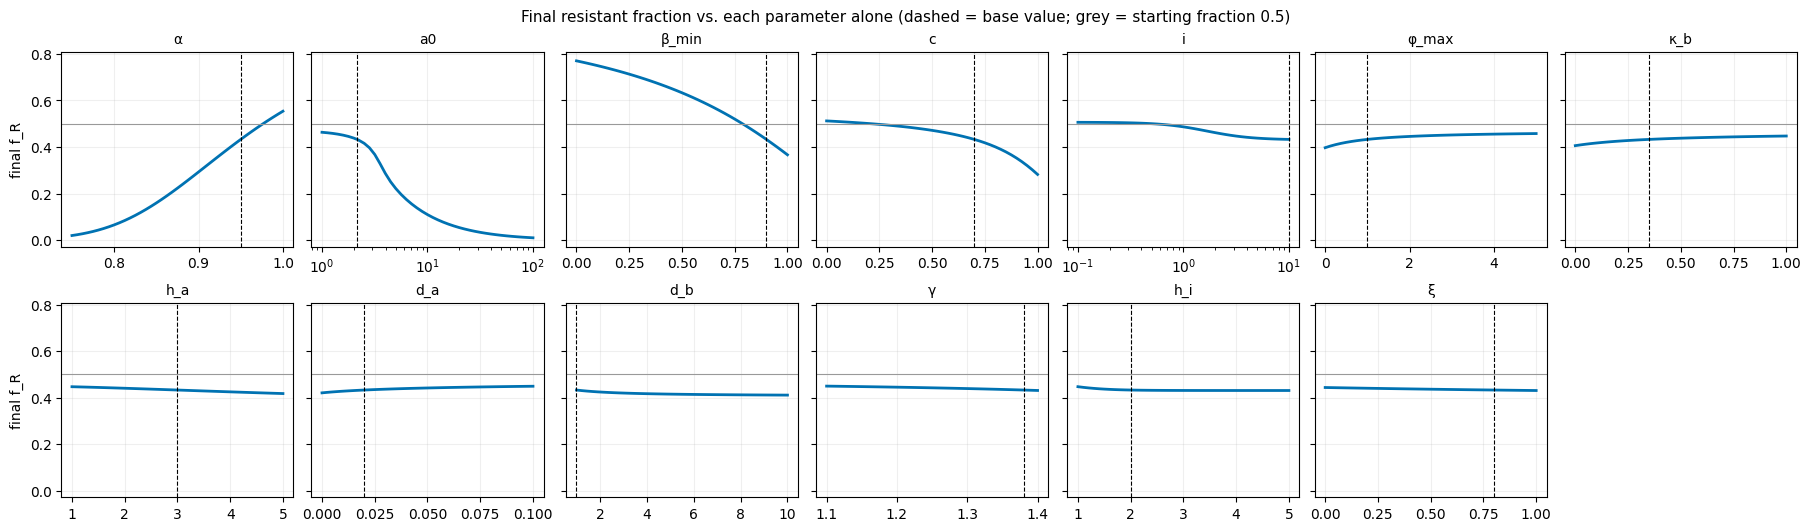

In [7]:
order = span.f_R_final.sort_values(ascending=False).index
fig, axes = plt.subplots(2, 7, figsize=(18, 5.2), constrained_layout=True, sharey=True)
for ax, k in zip(axes.flat, order):
    s = oat[oat.parameter == k].sort_values("value")
    ax.plot(s.value, s.f_R_final, color=OKABE_ITO["blue"], lw=2)
    if k in LOG_AXES: ax.set_xscale("log")
    ax.axvline(BASE_VALUES[k], color="black", ls="--", lw=0.8); ax.axhline(0.5, color="0.6", lw=0.8)
    ax.set_title(SHORT[k], fontsize=10); ax.grid(alpha=0.2)
axes.flat[-1].axis("off")
axes[0, 0].set_ylabel("final f_R"); axes[1, 0].set_ylabel("final f_R")
fig.suptitle("Final resistant fraction vs. each parameter alone (dashed = base value; grey = starting fraction 0.5)", fontsize=11)
plt.show()

**All strain parameters at once.** 10,000 random strains (all 11 strain parameters drawn together:
the paper's 10 randomized parameters plus d_a over the group's range) at the base dose. Rank correlations show which parameters still
matter when everything else varies too.

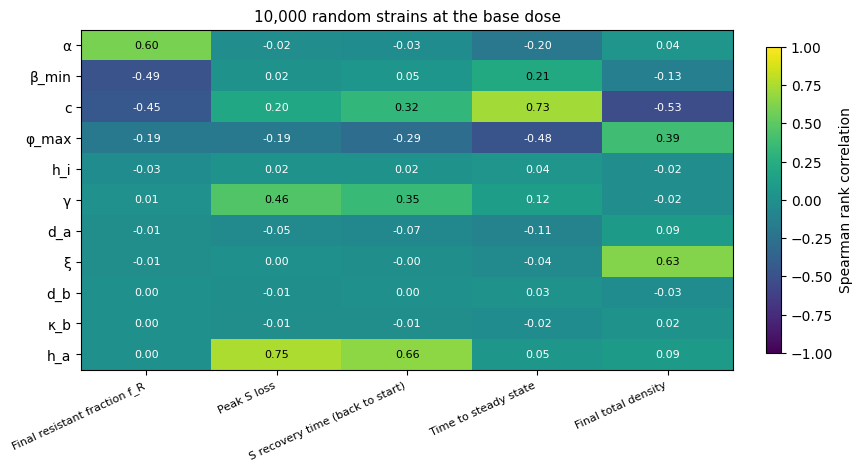

R gained in 43.2% of random strains; S viable at the end in 87.8%


,plain model: runs,plain model: % of grid,with floor: runs,with floor: % of grid
R cleared,10.0,0.10,0.0,0.00
R suppressed,7.0,0.07,5.0,0.05
"S viable, R persists",8764.0,87.64,8764.0,87.64
"S not viable, R persists",1217.0,12.17,1216.0,12.16
community collapsed,2.0,0.02,0.0,0.00
"R eradicated, S survives",0.0,0.00,5.0,0.05
"R eradicated, S not viable",0.0,0.00,3.0,0.03
community eradicated,0.0,0.00,7.0,0.07


In [8]:
ok = rnd[~rnd.outcome.isin(["community collapsed", "not converged"])]
ends = ["f_R_final", "peak_loss_S", "t_regain_S", "t_steady_state", "total_final"]
rho = pd.DataFrame({label(e): [ok[[p, e]].corr(method="spearman").iloc[0, 1] for p in STRAIN_PARAMS] for e in ends},
                   index=[SHORT[p] for p in STRAIN_PARAMS])
rho = rho.reindex(rho.iloc[:, 0].abs().sort_values(ascending=False).index)
fig, ax = plt.subplots(figsize=(8.5, 4.6), constrained_layout=True)
im = ax.imshow(rho.values, cmap="viridis", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(ends))); ax.set_xticklabels(rho.columns, rotation=25, ha="right", fontsize=8)
ax.set_yticks(range(len(rho))); ax.set_yticklabels(rho.index)
for r in range(rho.shape[0]):
    for c_ in range(rho.shape[1]):
        ax.text(c_, r, f"{rho.values[r, c_]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if rho.values[r, c_] < 0.2 else "black")
fig.colorbar(im, ax=ax, shrink=0.9).set_label("Spearman rank correlation")
ax.set_title("10,000 random strains at the base dose", fontsize=11)
plt.show()
print(f"R gained in {(rnd.delta_log_ratio > 0).mean():.1%} of random strains; S viable at the end in {rnd.sensitive_survives.mean():.1%}")
pd.concat([outcome_counts(rnd, "outcome").add_prefix("plain model: "), outcome_counts(rnd, "outcome_floor").add_prefix("with floor: ")], axis=1).fillna(0)

**Reading the two views together**

- **Composition (final f_R) is decided by the resistance traits and the antibiotic dose.** One at a
  time, f_R moves by 0.53 over the range of α, 0.45 over a0, 0.40 over β_min and 0.23 over c; every
  other parameter moves it by less than 0.08. With all strain parameters varied together the same
  three stand out (rank correlations +0.60 for α, −0.49 for β_min, −0.45 for c), followed weakly by
  φ_max (−0.19); the rest are indistinguishable from zero. This is in line with the paper's finding that
  parameters other than α, β_min and c do not strongly affect the selection outcome. These spans are
  for one parameter at a time at the base dose; combined slow antibiotic removal, or a higher dose,
  lowers f_R much further (sections 5, 10 and 12).
- **The depth of the crash is decided by the killing parameters.** Peak S loss is driven by the dose
  (0 to 100% over its range), then by h_a and γ (rank correlations 0.75 and 0.46 in the random
  strains), and by how quickly the antibiotic is removed (φ_max, c, κ_b, d_a).
- **Final biomass is decided by ξ**, the share of lysed biomass that is recycled (2.5 units over its
  range), then by φ_max and c.
- **h_i, d_b, κ_b and d_a have little effect on anything in the random strains.** They only matter in
  their own slices of parameter space (notebooks 04 and 05).
- The parameters that suppress R (low α, high β_min, high c) and the ones that set the crash (dose,
  h_a, γ) are largely different sets. Only c and the antibiotic dose are in both.

## 5. The four parameter groups in brief

### α, β_min, c (notebook 02)

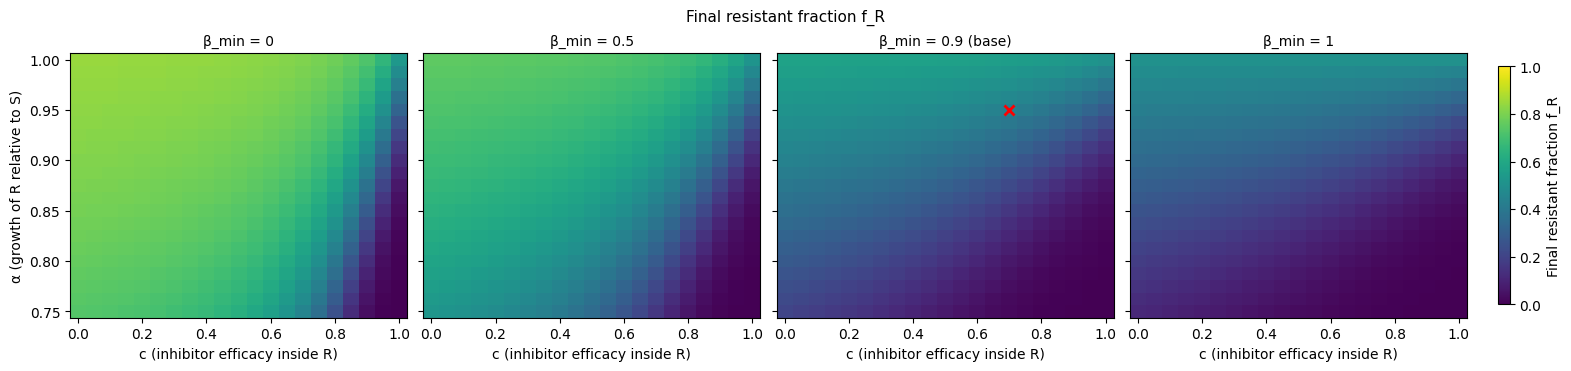

In [9]:
df = grids["α, β_min, c"]
heatmap_slices(df, "c", "alpha", "f_R_final", "beta_min", [0.0, 0.5, 0.9, 1.0], vmin=0, vmax=1); plt.show()

- R gains in 54% of this grid; lower α, higher β_min and higher c all push towards S.
- R is never eliminated at the Fig. 2C dose: the lowest final f_R is 9 × 10⁻⁴ and R never comes
  within five orders of magnitude of one cell.
- S stays viable in 81.6% of runs; it is lost only with strong private protection (β_min ≤ 0.55) and
  an imperfect inhibitor (c ≤ 0.9).
- c sets the depth of the crash: median peak S loss rises from 18% (c = 0) to 64% (c = 1).

### γ, h_a, a0 (notebook 03)

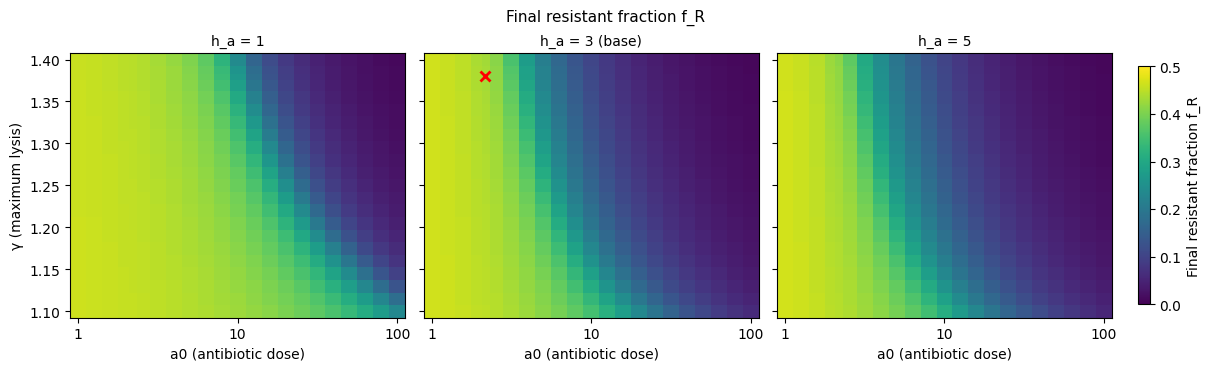

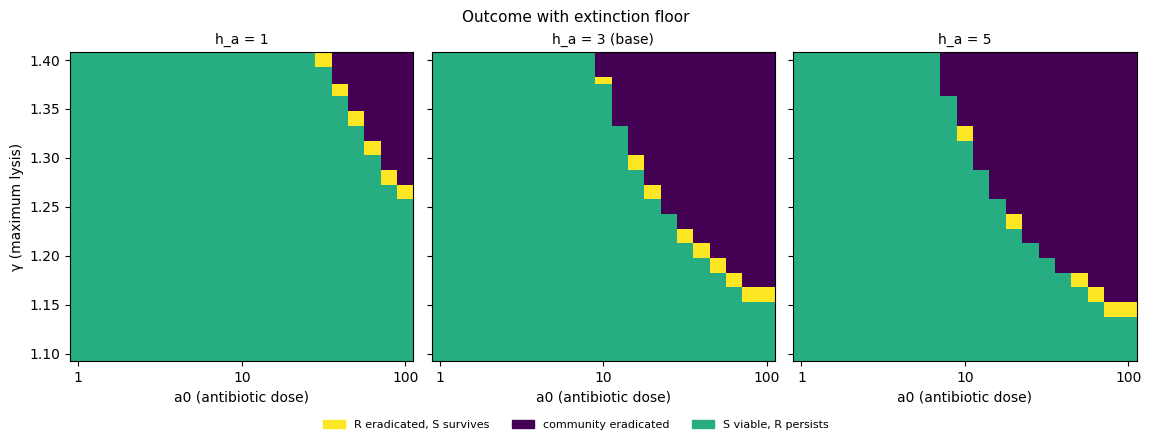

In [10]:
df = grids["γ, h_a, a0"].copy()
df["log10_ns_min"] = np.log10(df.ns_min.clip(lower=1e-30))
heatmap_slices(df, "a0", "gamma", "f_R_final", "h_a", [1.0, 3.0, 5.0], vmin=0, vmax=0.5); plt.show()
outcome_map(df, "a0", "gamma", "h_a", [1.0, 3.0, 5.0]); plt.show()

- Dose dominates composition (rank correlation with f_R: −0.96); γ and h_a mostly move the killing
  threshold a* = (γ − 1)^(−1/h_a), below which S does not decline (lysis is slower than growth; 1.38 at base).
- S gains in every run of this grid: with the base resistance traits and i = 10 no antibiotic dose
  makes R win.
- High doses produce extreme bottlenecks (lowest S of 2 × 10⁻²⁴ at a0 = 100 with base γ and h_a) and recovery times up to
  ~290. In the plain model every run regrows; with the extinction floor 24% of runs are eradicated
  outright and only 1.7% remove R while keeping S, in a band one grid cell wide.

### i, h_i, d_b (notebook 04)

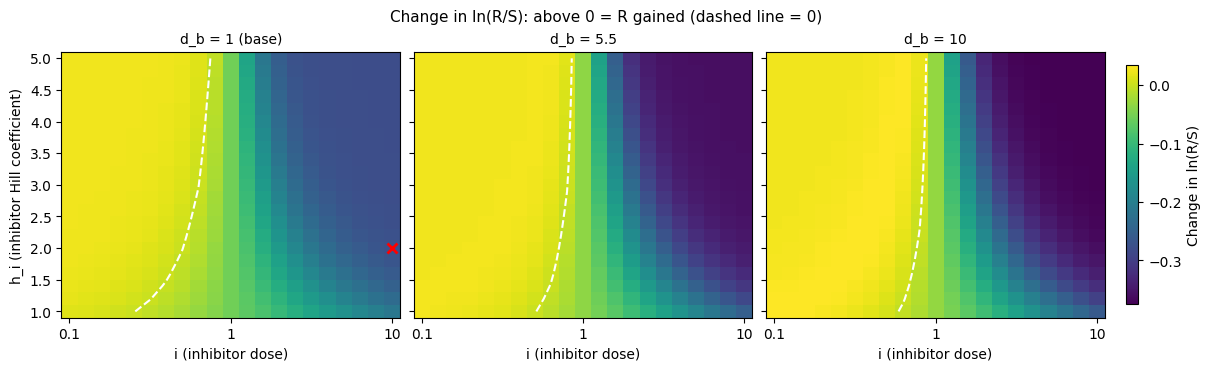

In [11]:
df = grids["i, h_i, d_b"]
heatmap_slices(df, "i", "h_i", "delta_log_ratio", "d_b", [1.0, 5.5, 10.0], diverging=True,
               title="Change in ln(R/S): above 0 = R gained (dashed line = 0)"); plt.show()

- The inhibitor dose flips the direction of selection: R gains for i below about 0.5, S gains above.
  At this antibiotic dose the effect is modest (f_R between 0.41 and 0.51).
- i and h_i act only through ι = i^h_i/(1 + i^h_i), so h_i only changes how quickly ι saturates with dose (it raises ι for i > 1 and lowers it for i < 1).
- More inhibitor (and faster enzyme inactivation, d_b) deepens the crash for both strains: peak S loss
  19% at i = 0.1, 39% at i = 10, 54% with d_b = 10.
- Of the inhibitor's three actions, removing R's private protection is the one that selects against
  R; blocking antibiotic degradation alone favours R and causes most of the deeper crash.

### κ_b, d_a, φ_max, ξ (notebook 05)

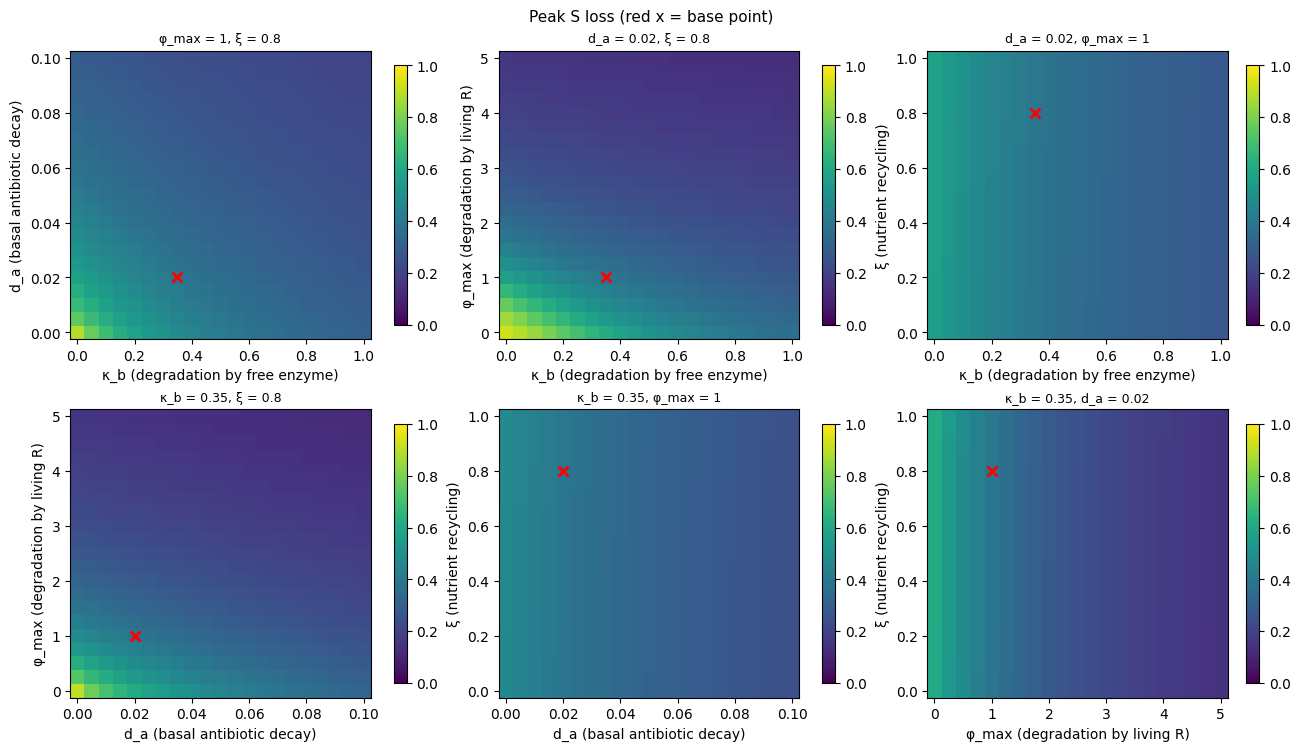

In [12]:
df = grids["κ_b, d_a, φ_max, ξ"]
pair_heatmaps(df, ["kappa_b", "d_a", "phi_max", "xi"], "peak_loss_S", vmin=0, vmax=1); plt.show()

- These four parameters change the crash and the recovery, not who wins: S gains in every run and 91.5%
  of settled runs end with f_R between 0.38 and 0.46 (when varied at the base dose).
- Degradation by living R (φ_max) dominates: from φ_max = 0 to 5, peak S loss falls from 61% to 15%
  and recovery time from 17 to 3. κ_b and d_a act the same way, more weakly.
- ξ mainly sets how much biomass comes back (final total 1.92 at ξ = 0, 4.40 at ξ = 1).
- The community collapses only when the antibiotic is removed too slowly: 350 runs (0.18%), all with
  d_a = 0, κ_b ≤ 0.3 and φ_max ≤ 0.75.

## 6. The dose plane: antibiotic dose × inhibitor dose

No parameter group swept the two doses together, so this fills the gap, for four strains along the
directions of the paper's Fig. 3A (base; α = 0.8; β_min = 0.7; c = 0.9; values chosen by the group). Top: final resistant fraction in the plain model. Bottom: outcome with the
extinction floor.

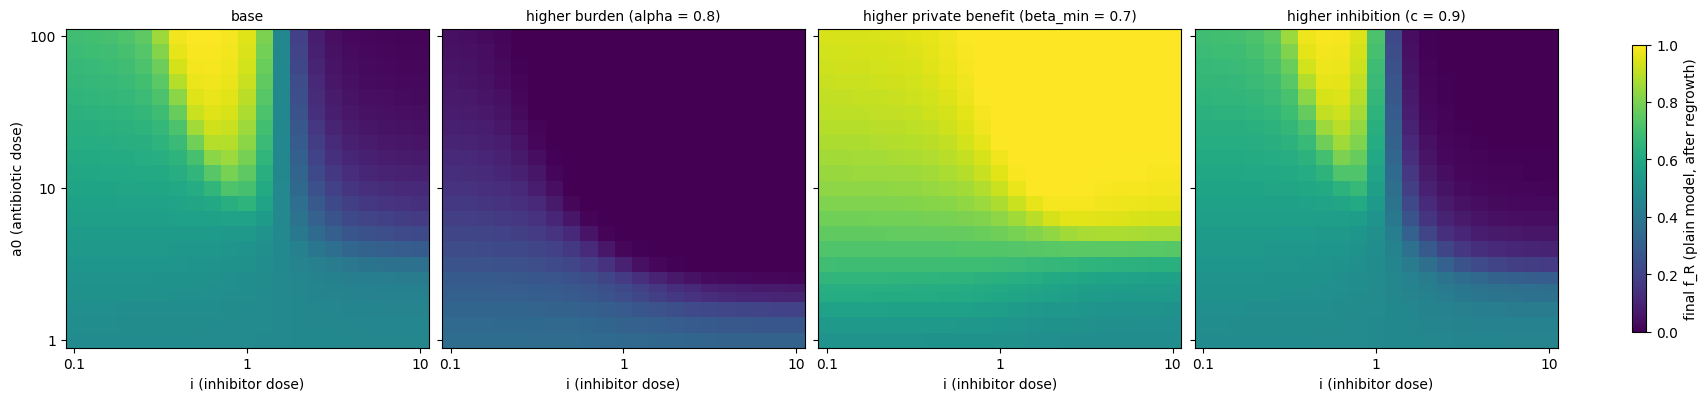

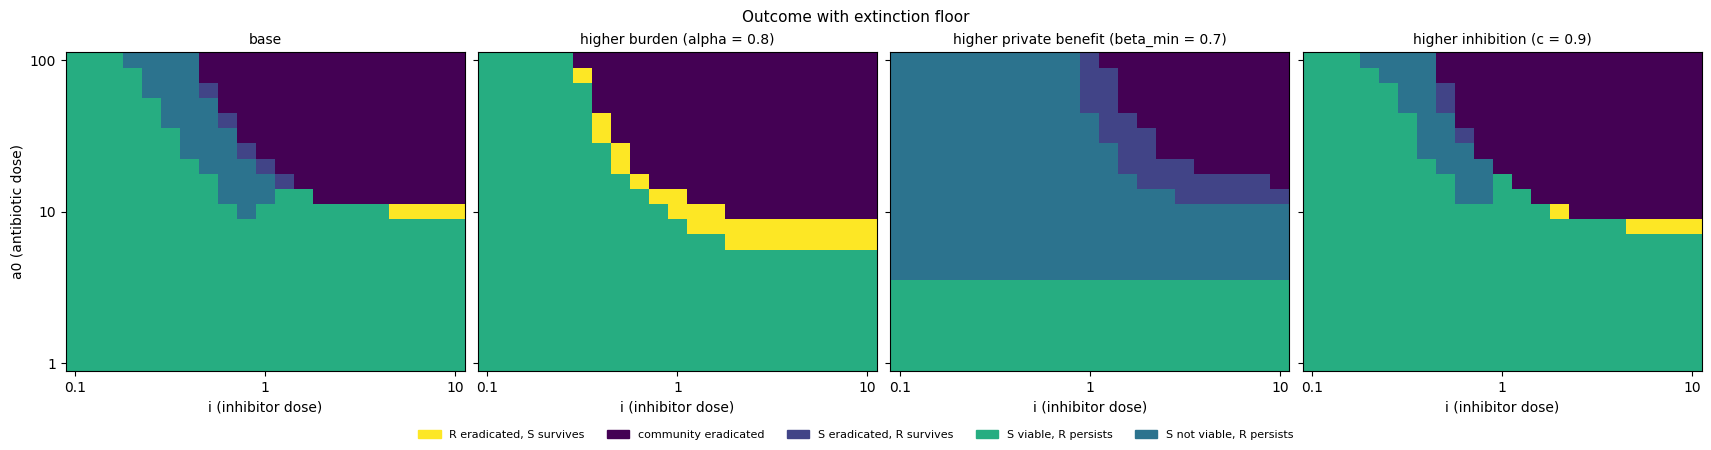

outcome_floor,"R eradicated, S survives",community eradicated,"S eradicated, R survives","S viable, R persists","S not viable, R persists"
strain,,,,,
base,4,116,5,305,32
higher burden (alpha = 0.8),29,145,0,288,0
higher private benefit (beta_min = 0.7),0,65,31,147,219
higher inhibition (c = 0.9),5,128,3,301,25


In [13]:
strains = list(dose.strain.unique())
fig, axes = plt.subplots(1, 4, figsize=(17, 3.9), constrained_layout=True, sharey=True)
for ax, sname in zip(axes, strains):
    piv = dose[dose.strain == sname].pivot(index="a0", columns="i", values="f_R_final")
    m = ax.pcolormesh(np.log10(piv.columns), np.log10(piv.index), piv.values, cmap="viridis", vmin=0, vmax=1, shading="nearest")
    ax.set_title(sname, fontsize=10); ax.set_xticks([-1, 0, 1]); ax.set_xticklabels(["0.1", "1", "10"]); ax.set_xlabel(label("i"))
axes[0].set_yticks([0, 1, 2]); axes[0].set_yticklabels(["1", "10", "100"]); axes[0].set_ylabel(label("a0"))
fig.colorbar(m, ax=axes, shrink=0.9).set_label("final f_R (plain model, after regrowth)")
plt.show()

present = [o for o in engine.OUTCOME_FLOOR_ORDER if o in set(dose.outcome_floor)]
code_of = {o: k for k, o in enumerate(present)}
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
cmap = ListedColormap([OUTCOME_COLORS[o] for o in present]); norm = BoundaryNorm(np.arange(-0.5, len(present)), cmap.N)
fig, axes = plt.subplots(1, 4, figsize=(17, 4.4), constrained_layout=True, sharey=True)
for ax, sname in zip(axes, strains):
    sub = dose[dose.strain == sname].assign(code=lambda d: d.outcome_floor.map(code_of))
    piv = sub.pivot(index="a0", columns="i", values="code")
    ax.pcolormesh(np.log10(piv.columns), np.log10(piv.index), piv.values, cmap=cmap, norm=norm, shading="nearest")
    ax.set_title(sname, fontsize=10); ax.set_xticks([-1, 0, 1]); ax.set_xticklabels(["0.1", "1", "10"]); ax.set_xlabel(label("i"))
axes[0].set_yticks([0, 1, 2]); axes[0].set_yticklabels(["1", "10", "100"]); axes[0].set_ylabel(label("a0"))
fig.legend(handles=[Patch(color=OUTCOME_COLORS[o], label=o) for o in present], loc="outside lower center", ncol=len(present), fontsize=8, frameon=False)
fig.suptitle("Outcome with extinction floor", fontsize=11)
plt.show()
pd.crosstab(dose.strain, dose.outcome_floor).reindex(strains)[present]

- **Base strain.** R gains at high antibiotic when the inhibitor dose is below about 1 (f_R 0.64–0.75 at the
  lowest inhibitor doses, up to 0.99 at i ≈ 0.5–0.8 in runs that pass below one cell) and loses at
  high inhibitor: the pattern of the paper's Fig. 2D. With the floor, most of the high-dose corner is
  eradicated outright; R is removed with S kept at only 4 of 462 dose combinations.
- **Higher burden (α = 0.8).** S gains at every dose. This is the only strain where the plain model
  itself clears R (f_R < 10⁻⁹ at 104 dose combinations), and the "R eradicated, S survives" window is
  widest (29 combinations, a0 from about 6 to 80).
- **Higher private benefit (β_min = 0.7).** R gains at 97% of dose combinations, and at 31 of them
  treatment eradicates S and leaves R: the opposite of the goal.
- **Higher inhibition (c = 0.9).** Close to the base strain, with slightly more room for S.

## 7. The goal: remove R and keep S

Two ways to count success:

- **Plain model:** R ends below f_R = 10⁻⁹ (less than one cell per 10⁹) while S is viable.
- **With the extinction floor:** R falls below one cell at some point and is gone for good, while S
  never does and ends viable.

In [14]:
rows = []
all_tables = {**grids, "dose plane (4 strains)": dose, "random strains (base dose)": rnd, "criterion grid (a0 = 100)": crit}
for name, df in all_tables.items():
    plain = (df.outcome == "R cleared") & df.sensitive_survives
    rows.append({"table": name, "runs": len(df),
                 "plain model: R cleared, S viable": int(plain.sum()),
                 "with floor: R eradicated, S viable": int(df.goal_met_floor.sum()),
                 "with floor: community eradicated": int((df.outcome_floor == "community eradicated").sum()),
                 "with floor: S eradicated, R survives": int((df.outcome_floor == "S eradicated, R survives").sum())})
goal = pd.DataFrame(rows).set_index("table")
goal

,runs,"plain model: R cleared, S viable","with floor: R eradicated, S viable",with floor: community eradicated,"with floor: S eradicated, R survives"
table,,,,,
"α, β_min, c",9261,0,0,0,0
"γ, h_a, a0",10164,0,172,2475,0
"i, h_i, d_b",9261,0,0,0,0
"κ_b, d_a, φ_max, ξ",194481,0,0,350,0
dose plane (4 strains),1848,104,38,454,39
random strains (base dose),10000,7,5,7,0
criterion grid (a0 = 100),9261,1769,0,5327,807


### How robust is the "R eradicated, S survives" window?

The window exists only where the lowest R density is below one cell and the lowest S density is
above it. Its size therefore depends on (a) how far apart S and R are at the bottom of the crash and
(b) where exactly the one-cell line is. Below: the ratio lowest-S / lowest-R, and the share of the
dose plane inside the window as the assumed culture size changes.

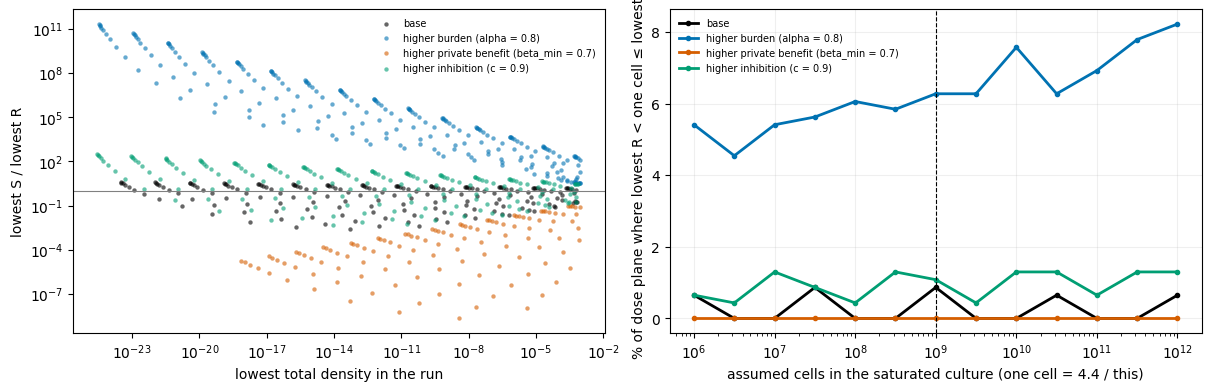

                                         runs     a0_min     a0_max     i_min  i_max
strain                                                                              
base                                      4.0  10.000000  10.000000  5.011872   10.0
higher burden (alpha = 0.8)              29.0   6.309573  79.432823  0.316228   10.0
higher private benefit (beta_min = 0.7)   NaN        NaN        NaN       NaN    NaN
higher inhibition (c = 0.9)               5.0   7.943282  10.000000  1.995262   10.0


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
cols = [OKABE_ITO["black"], OKABE_ITO["blue"], OKABE_ITO["vermillion"], OKABE_ITO["green"]]
deep = dose[dose.total_min < 1e-3]
for sname, colr in zip(strains, cols):
    s = deep[deep.strain == sname]
    axes[0].scatter(s.total_min, s.ns_min / s.nr_min, s=10, color=colr, alpha=0.6, lw=0, label=sname)
axes[0].set(xscale="log", yscale="log", xlabel="lowest total density in the run", ylabel="lowest S / lowest R")
axes[0].axhline(1, color="0.5", lw=0.8); axes[0].legend(frameon=False, fontsize=7)
cells = 10.0 ** np.arange(6, 12.5, 0.5)
for sname, colr in zip(strains, cols):
    s = dose[dose.strain == sname]
    share = [((s.nr_min < engine.CARRYING_CAPACITY / n) & (s.ns_min >= engine.CARRYING_CAPACITY / n)).mean() for n in cells]
    axes[1].plot(cells, np.array(share) * 100, color=colr, lw=2, marker="o", ms=3, label=sname)
axes[1].axvline(engine.CELLS_AT_SATURATION, color="black", ls="--", lw=0.8)
axes[1].set(xscale="log", xlabel="assumed cells in the saturated culture (one cell = 4.4 / this)", ylabel="% of dose plane where lowest R < one cell ≤ lowest S")
axes[1].grid(alpha=0.2); axes[1].legend(frameon=False, fontsize=7)
plt.show()
g = dose[dose.goal_met_floor]
print(g.groupby("strain").agg(runs=("a0", "size"), a0_min=("a0", "min"), a0_max=("a0", "max"), i_min=("i", "min"), i_max=("i", "max")).reindex(strains))

- **In the plain model, R is essentially never removed while S is kept at the Fig. 2C dose.** None of
  the four parameter grids contains a single such run, and only 7 of 10,000 random strains do.
- **At very high dose the plain model appears to succeed, but it is the regrowth artefact.** At
  a0 = 100, R ends below 10⁻⁹ with S viable in 1,769 of 9,261 strains (19%). In every one of them both
  populations had fallen far below one cell first; with the extinction floor none of them counts
  (5,327 are eradicated outright and in 807 S is eradicated while R survives).
- **With the extinction floor, the window is narrow.** R is eradicated with S kept in 172 runs of the
  γ, h_a, a0 grid (1.7%), 38 dose combinations on the dose plane (29 of them for the high-burden
  strain) and 5 of 10,000 random strains.
- **Why it is narrow: S and R crash together.** Both are killed by the same lysis term; they separate
  only through the cost of resistance and R's private protection. At the base strain the lowest S is
  never more than about 4 times the lowest R, so a dose strong enough to push R below one cell almost
  always takes S with it. With a larger burden (α = 0.8) the two separate by many orders of magnitude
  and the window opens.
- **The window for the base strain is narrow at every assumed culture size.** From 10⁶ to 10¹² cells
  the dose that eradicates S is only 3–5% above the one that eradicates R (ratio 1.03–1.05), less than
  the 1.26 step of the dose grid, so whether a grid dose lands in it is chance (0% to 0.9% of the dose
  plane in the right-hand panel above). For α = 0.8 the ratio is 1.44–1.87 and the share stays between 5% and 8%.
- **Wrong treatment can do the opposite.** With a larger private benefit (β_min = 0.7), 31 dose
  combinations eradicate S and leave R.
- **What success needs.** The five successful random strains all combine a large burden (α ≤ 0.88),
  a strong inhibitor (c of about 0.8 or more) and very slow antibiotic decay: a long exposure during which the S-R
  gap can grow, rather than a harder hit.

## 8. The paper's selection criterion (notebook 06)

In [16]:
g = DEFAULT_PARAMS.gamma
crit["margin"] = (1 - crit.c) * (1 - crit.beta_min) - (1 - crit.alpha) / g
crit["criterion_R"] = crit.margin > 0
crit["sim_R"] = crit.delta_log_ratio > 0
line = f"After full regrowth: agreement {(crit.criterion_R == crit.sim_R).mean():.1%} over {len(crit):,} strains"
ro_path = TABLES / "criterion_readout_t100.csv"
if ro_path.exists():
    ro = crit.merge(pd.read_csv(ro_path), on=["alpha", "beta_min", "c"])
    line = f"During treatment (t = 100): agreement {(ro.criterion_R == (ro.delta_log_ratio_t100 > 0)).mean():.1%} | " + line
print(line)
mm = crit[crit.criterion_R != crit.sim_R]
print(f"All mismatches after regrowth lie within |margin| <= {mm.margin.abs().max():.3f} of the criterion boundary")

During treatment (t = 100): agreement 99.2% | After full regrowth: agreement 93.7% over 9,261 strains
All mismatches after regrowth lie within |margin| <= 0.069 of the criterion boundary


- Read during treatment, the paper's simplified criterion agrees with the simulation for 99.2% of
  strains; the few mismatches sit within 0.01 of its boundary.
- Read after full regrowth the agreement is 93.7%: the criterion over-predicts R near its boundary
  (margin below 0.07), because S outgrows R once the antibiotic has gone. This is a plain-model
  comparison; with the extinction floor those strains are eradicated.
- The exact form of the criterion (Eq. 1) matches the code in 3,000 of 3,000 random states
  (notebook 00).

## 9. Dose plane × resistant-strain traits (notebook 08)

The full dose plane (462 doses) for 294 strains (α × β_min × c). **Window ratio** = (lowest antibiotic
dose that eradicates S) / (lowest that eradicates R); above 1 means a dose exists that removes R and keeps S.

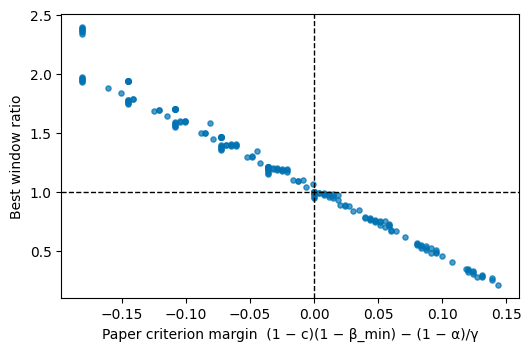

113 of 294 strains have a selective window; widest fully measured ratio 2.18; 7 strains have an open-ended window (S survives every dose up to a0 = 100), ratio at least 2.39
Criterion margin < 0 matches 'window exists' in 100.0% of strains


,strains,with_window,widest_ratio,most_goal_doses
alpha,,,,
0.75,49,30,2.39,53
0.80,49,26,1.94,47
0.85,49,23,1.70,34
0.90,49,19,1.46,26
0.95,49,15,1.21,14
1.00,49,0,1.00,0


In [17]:
from src.analysis.dose_window import strain_summary
joint = pd.read_csv(TABLES / "grid_dose_by_trait_joint.csv.gz")
js = strain_summary(joint)
js["criterion_margin"] = (1 - js.c) * (1 - js.beta_min) - (1 - js.alpha) / BASE_VALUES["gamma"]
has = js.best_window_ratio > 1
fig, ax = plt.subplots(figsize=(5.2, 3.4), constrained_layout=True)
ax.scatter(js.criterion_margin, js.best_window_ratio, s=14, color="#0072B2", alpha=0.7)
ax.axhline(1, color="black", ls="--", lw=1); ax.axvline(0, color="black", ls="--", lw=1)
ax.set_xlabel("Paper criterion margin  (1 − c)(1 − β_min) − (1 − α)/γ"); ax.set_ylabel("Best window ratio")
plt.show()
print(f"{has.sum()} of {len(js)} strains have a selective window; widest fully measured ratio {js.widest_measured_ratio.max():.2f}; "
      f"{int(js.best_is_lower_bound.sum())} strains have an open-ended window (S survives every dose up to a0 = 100), ratio at least {js[js.best_is_lower_bound].best_window_ratio.max():.2f}")
print(f"Criterion margin < 0 matches 'window exists' in {((js.criterion_margin < 0) == has).mean():.1%} of strains")
js.groupby("alpha").agg(strains=("c", "size"), with_window=("best_window_ratio", lambda s: (s > 1).sum()),
                        widest_ratio=("best_window_ratio", "max"), most_goal_doses=("goal_doses", "max")).round(2)

- **Changing the dose makes the goal reachable, but only for some strains.** 113 of 294 strains have a
  dose window that removes R and keeps S.
- **The window is narrow:** ratio 1.04 for the base strain and 2.18 for the widest window that is
  fully measured (α = 0.75, β_min = 1; at the lowest inhibitor doses the same strains have an open-ended
  window of at least 2.4, because S survives every dose up to a0 = 100). Lower α widens it most;
  strong private protection (low β_min) closes it unless c is near 1.
- **The paper's criterion is a close guide to it.** On this grid the sign of the Eq. 2 margin,
  (1 − c)(1 − β_min) − (1 − α)/γ, matches the presence of a window in all 294 strains (the 99 strains
  where R is never eradicated count as no window). This is empirical and the grid is coarse: strains
  just on the R-favoured side of the boundary can still have a very narrow window (notebook 08).

## 10. Fine grid in the low-degradation corner (notebook 09)

The base values of φ_max and κ_b sit low in the paper's ranges, so the corner between zero and the base
point is covered by only 5 × 8 values on the standard grid. Notebook 09 covers it with 21 × 21 values
(φ_max 0-1, κ_b 0-0.35) for each of the 21 values of d_a.

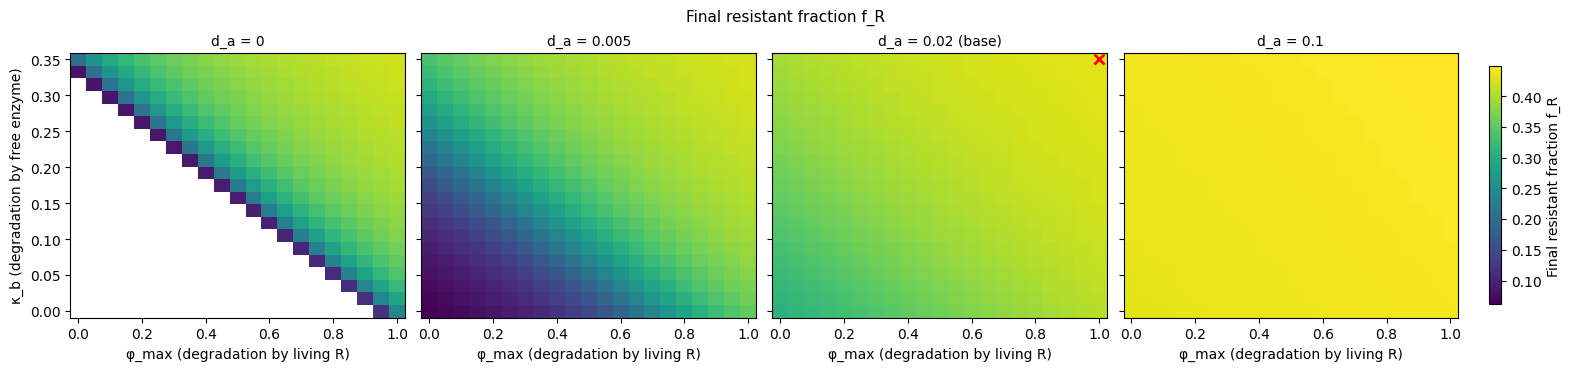

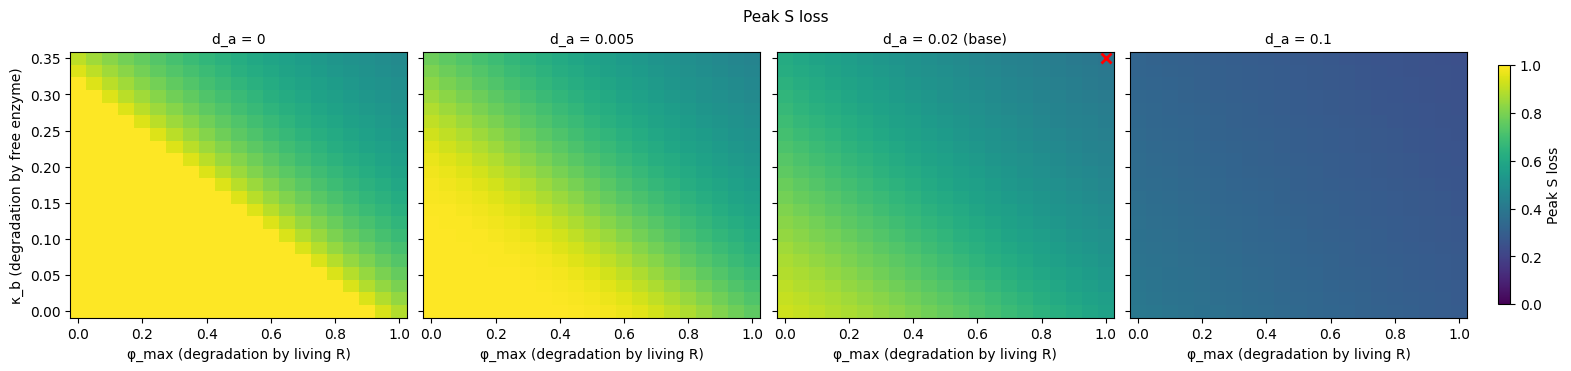

9,261 runs; 190 collapsed (all at d_a = 0: True)
f_R 0.061-0.449; peak S loss 25%-100%; goal met in 0 runs


In [18]:
fine = pd.read_csv(TABLES / "grid_fine_phimax_kappab_da.csv")
heatmap_slices(fine, "phi_max", "kappa_b", "f_R_final", "d_a", [0.0, 0.005, 0.02, 0.1]); plt.show()
heatmap_slices(fine, "phi_max", "kappa_b", "peak_loss_S", "d_a", [0.0, 0.005, 0.02, 0.1], vmin=0, vmax=1); plt.show()
ok = fine[fine.outcome != "community collapsed"]
print(f"{len(fine):,} runs; {len(fine) - len(ok)} collapsed (all at d_a = 0: {(fine[fine.outcome == 'community collapsed'].d_a == 0).all()})")
print(f"f_R {ok.f_R_final.min():.3f}-{ok.f_R_final.max():.3f}; peak S loss {ok.peak_loss_S.min():.0%}-{ok.peak_loss_S.max():.0%}; goal met in {int(fine.goal_met_floor.sum())} runs")

- **Same ranges as the standard grid, eleven times the resolution** (441 instead of 40 points per plane).
- **Slow drug removal lowers R's share but deepens the crash:** f_R falls to 0.06 and peak S loss reaches
  100% at d_a = 0.005 with no enzyme removal. At d_a = 0.1 the plane is flat.
- **The two enzyme routes are nearly interchangeable** (f_R is almost a function of u = φ_max + κ_b / 0.35),
  and with d_a = 0 the community collapses when u ≤ 0.90.
- **No run meets the goal:** neither strain falls below one cell in any settled run.

## 11. Killing rate vs. private protection (notebook 10)

From the model equations, d ln(R/S)/dt = g(s)·[γ·H(a)·p − (1 − α)], with p = 1 − β the fraction of lysis
R avoids. The neutral protection p* (R neither gains nor loses) is found by root-finding for each γ.
γ is extended to 3.1 here, beyond the paper's 1.1-1.4.

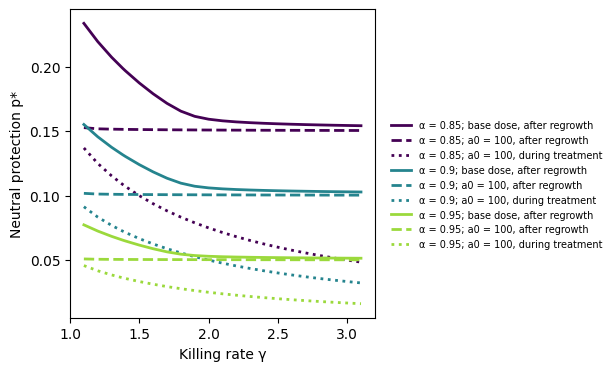

During treatment: largest |p* − (1 − α)/γ| = 0.0007
After regrowth at a0 = 100, α = 0.95: p* from 0.0502 to 0.0509 over γ = 1.1-3.1 (1 − α = 0.05)


In [19]:
neutral = pd.read_csv(TABLES / "neutral_lines_gamma_protection.csv")
labels = {(2.15, "final"): ("-", "base dose, after regrowth"), (100.0, "final"): ("--", "a0 = 100, after regrowth"),
          (100.0, "100"): (":", "a0 = 100, during treatment")}
fig, ax = plt.subplots(figsize=(6, 3.6), constrained_layout=True)
for al, col in zip((0.85, 0.90, 0.95), plt.cm.viridis([0.0, 0.45, 0.85])):
    for (a0, readout), (ls, lab) in labels.items():
        g = neutral[(neutral.a0 == a0) & (neutral.readout == readout) & (neutral.alpha == al)].sort_values("gamma")
        ax.plot(g.gamma, g.p_neutral, color=col, ls=ls, lw=2, label=f"α = {al:g}; {lab}")
ax.set(xlabel="Killing rate γ", ylabel="Neutral protection p*")
fig.legend(*ax.get_legend_handles_labels(), loc="outside right center", frameon=False, fontsize=7)
plt.show()
t = neutral[(neutral.a0 == 100.0) & (neutral.readout == "100")]
print(f"During treatment: largest |p* − (1 − α)/γ| = {(t.p_neutral - t.p_criterion).abs().max():.4f}")
f = neutral[(neutral.a0 == 100.0) & (neutral.readout == "final") & (neutral.alpha == 0.95)]
print(f"After regrowth at a0 = 100, α = 0.95: p* from {f.p_neutral.min():.4f} to {f.p_neutral.max():.4f} over γ = 1.1-3.1 (1 − α = 0.05)")

- **Lysis rates are exactly linear in protection,** by construction of the model.
- **During treatment the trade-off is inverse:** p* = (1 − α)/γ, a straight line against 1/γ and a curve
  against γ.
- **After full regrowth the killing rate almost stops mattering:** p* = (1 − α)/(1 − ΔlnS/G) exactly, which
  tends to 1 − α when killing is strong (G = total growth, ΔlnS = net change of ln S).
- The killing R suffers is linear in protection only when killing is strong; the killing of S falls as
  R's protection rises, but not linearly.

## 12. Killing rate vs. degradation by living R (notebook 11)

φ_max does not enter the equation for the R/S ratio, so the test is empirical: for each γ, the φ_max that
holds an endpoint fixed (a line of equal outcome), followed up to φ_max = 40.

In [20]:
from src.analysis.kill_protection import linear_fit
iso = pd.read_csv(TABLES / "iso_lines_gamma_phimax.csv")
iso = iso[~((iso.endpoint == "peak_loss_S") & (iso.level > 0.99995))].dropna()
rows = []
for (a0, e, lv), g in iso.groupby(["a0", "endpoint", "level"]):
    if len(g) >= 3:
        f = linear_fit(g.gamma, g.phi_iso)
        rows.append({"dose a0": a0, "held fixed": ("final f_R" if e == "f_R_final" else "peak S loss") + f" = {lv:.4g}",
                     "slope (φ_max per unit γ)": f["slope"], "R²": f["r2"], "largest deviation": f["max_dev"]})
lines = pd.DataFrame(rows).set_index(["dose a0", "held fixed"])
print(f"{len(lines)} lines; R² from {lines['R²'].min():.4f} to {lines['R²'].max():.4f}")
lines.round(4)

11 lines; R² from 0.9936 to 0.9997


slope (φ_max per unit γ)      R²  largest deviation
dose a0 held fixed                                                               
2.15    final f_R = 0.4326                      6.8413  0.9939             0.0549
        peak S loss = 0.3944                   19.0853  0.9961             0.0423
        peak S loss = 0.5                      15.2368  0.9968             0.0344
        peak S loss = 0.9                       8.5030  0.9983             0.0278
        peak S loss = 0.99                      7.7522  0.9991             0.0192
        peak S loss = 0.9999                    7.7600  0.9995             0.0137
10.00   final f_R = 0.1094                     20.9741  0.9936             0.0532
        peak S loss = 0.5                      49.3334  0.9989             0.0207
        peak S loss = 0.9                      28.3549  0.9991             0.0221
        peak S loss = 0.99                     25.9161  0.9995             0.0153
        peak S loss = 0.9999                   25.7374  0.9997             0.0108

- **Close to linear, with a slope that rises along each line:** a straight line fits every line of equal
  outcome with R² ≥ 0.994, but all of them bend upward.
- **The exchange rate is steep:** on average +0.1 in γ needs +0.8 to +1.9 more φ_max at the base dose and
  +2.6 to +4.9 at a0 = 10 to keep peak S loss unchanged (+0.7 and +2.1 to keep the final resistant
  fraction unchanged), against a φ_max range of 0–5 in the paper.
- So φ_max can offset only a narrow band of killing rates.

## 13. Conclusions

1. **The model is implemented correctly.** It reproduces the paper's Fig. 2C, the Fig. 2D example runs
   and the Fig. 3A dose maps, satisfies its conservation laws and exact limits, and gives the same
   answers with three ODE solvers. All verification checks pass.
2. **Who wins is decided by the resistance traits and the dose.** α, β_min and c (and the antibiotic
   and inhibitor doses) set the final resistant fraction; the other eight parameters move it by less
   than 0.08 each when varied alone at the base dose. This is in line with the paper. Combined slow
   antibiotic removal, or a higher dose, lowers R's share much further at the base traits and i = 10;
   at low inhibitor doses (i below about 1.3) a higher antibiotic dose makes R gain instead (section 6).
3. **How deep the crash is, is decided by a different set:** the dose, h_a and γ, and how fast the
   antibiotic is removed (φ_max, then κ_b and d_a). ξ mainly sets how much biomass comes back.
4. **Selection against R comes from one of the inhibitor's three actions.** Reducing R's private
   protection selects against R; reducing antibiotic degradation mainly deepens the crash for everyone
   and amplifies the effect (base-point ablation, notebook 04). i and h_i act only through ι.
5. **One dose does not remove R while keeping S, except in a narrow window.** S and R are killed
   together, so the plain model never achieves it at the Fig. 2C dose, and with a one-cell extinction
   floor it happens in under 2% of the dose sweep. A large cost of resistance widens the window; a
   large private benefit can turn treatment against S instead. Sweeping dose and traits together
   (notebook 08) shows a selective dose window in 113 of 294 strains, a factor of 2.2 at its widest measured (at least
   2.4 where it is open-ended), and present on that grid whenever the paper's criterion favours S.
6. **Diversity is not informative with two strains.** It is a function of the resistant fraction and
   cannot tell "R gone" from "S gone".
7. **The paper's selection criterion holds for the regime it describes** (99.2% during treatment) and
   over-predicts R near its boundary once regrowth is included (93.7%).
8. **Killing rate and private protection trade off inversely during treatment** (neutral protection
   p* = (1 − α)/γ), and after a full kill-and-regrow cycle the killing rate almost stops mattering
   (p* ≈ 1 − α). Lysis rates are linear in protection by construction (notebook 10).
9. **Killing rate and antibiotic degradation by living R trade off almost linearly** (R² ≥ 0.994 along
   lines of equal outcome, with a slope that rises along each line), but at a steep exchange rate, so
   φ_max offsets only a narrow band of γ (notebook 11).

## 14. Limits of this analysis and suggested next steps

**Limits**

- **One dose.** The model has no repeated dosing, dilution or nutrient refresh. The final state is a
  nutrient-exhausted batch culture.
- **The extinction floor is a rule added on top of a deterministic model.** It assumes 10⁹ cells at
  saturation. A stochastic model would be the proper treatment of small populations.
- **Two strains.** Community diversity in a meaningful sense needs more taxa.
- **The inhibitor does not decay,** and free enzyme is only removed by the inhibitor.
- **d_a range.** 0-0.1 is the group's choice; the paper does not randomize d_a.
- **Viability yardstick.** "S viable" is measured against one fixed reference (the base mixture
  without drug) in every sweep.
- **Read-out time of the paper's dose maps** is not stated; t = 100 was assumed in notebook 00.
- **Notebooks 10 and 11 extend γ to 3.1,** beyond the paper's 1.1–1.4, and notebook 11 follows lines of
  equal outcome to φ_max = 40, beyond the paper's 0–5 (group choices, needed to see the shape).
- **The joint dose × trait sweep uses a coarse trait grid** (6 × 7 × 7 strains) and the standard dose
  grid, whose steps (factor 1.26) are wider than many of the selective windows.

**Suggested next steps**

1. Periodic dosing: repeat the dose with dilution, and ask whether a moderate dose held for longer
   widens the S-R gap without eradicating S (the successful random strains point this way).
2. Test how sensitive the results are to the viability definition (fixed reference, per-run drug-free
   control, or starting density).
3. More than two strains, so that diversity becomes a real endpoint.
4. The paper's own criterion protocol (minimum resistant fraction over suppressing doses) on a sample
   of strains.